<a href="https://colab.research.google.com/github/kkm1004ok-tech/Data-Analysis-with-Open-Source/blob/main/kaggle_%EC%8B%A4%EC%8A%B5%20%EC%A0%84%EC%B2%98%EB%A6%AC%EA%B9%8C%EC%A7%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 오픈소스 기반 데이터 분석 6강 - 데이터 전처리 1

## 6-5 실습 시나리오 - Kaggle을 활용한 데이터 수집 및 측정

- Kaggle([https://www.kaggle.com](https://www.kaggle.com)) 회원 가입
- Kaggle 접근 토큰 생성(API 키)


### Kaggle API 키 업로드

In [1]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"kkm1004ok","key":"9d671983c4749ad2b8bd392c754e4959"}'}

### Kaggle API 키 사용을 위한 Colab 환경 설정

In [2]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

### Kaggle 데이터셋 다운로드

In [3]:
!kaggle competitions download -c store-sales-time-series-forecasting

!unzip store-sales-time-series-forecasting.zip

100% 21.4M/21.4M [00:00<00:00, 133MB/s] 

Archive:  store-sales-time-series-forecasting.zip
  inflating: holidays_events.csv     
  inflating: oil.csv                 
  inflating: sample_submission.csv   
  inflating: stores.csv              
  inflating: test.csv                
  inflating: train.csv               
  inflating: transactions.csv        


### Kaggle 데이터셋 DataFrame 로드 및 살펴보기

In [4]:
import pandas as pd

# Grocery Sales 데이터 DataFrame 로드
train=pd.read_csv('train.csv')
stores=pd.read_csv('stores.csv')
transactions=pd.read_csv('transactions.csv')
oil=pd.read_csv('oil.csv')
holidays_events=pd.read_csv('holidays_events.csv')
# 판매 데이터 살펴보기
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


### Kaggle 데이터셋 측정

In [5]:
# 판매 데이터 기본 통계량
train.describe()
# 원유 가격 데이터 기본 정보
stores.head()
oil.head()

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [16]:
##matplotlib에서 한글...
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/u

In [7]:
##결측치 처리
print(train.isnull().sum())
print(stores.isnull().sum())
print(transactions.isnull().sum())
print(oil.isnull().sum())
print(holidays_events.isnull().sum())

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64
date            0
store_nbr       0
transactions    0
dtype: int64
date           0
dcoilwtico    43
dtype: int64
date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64


In [8]:
##시각화 라이브러리 가져오기
import numpy as np
import pandas as pd
import seaborn as sns
import missingno as msno



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47588 (\N{HANGUL SYLLABLE MAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/us

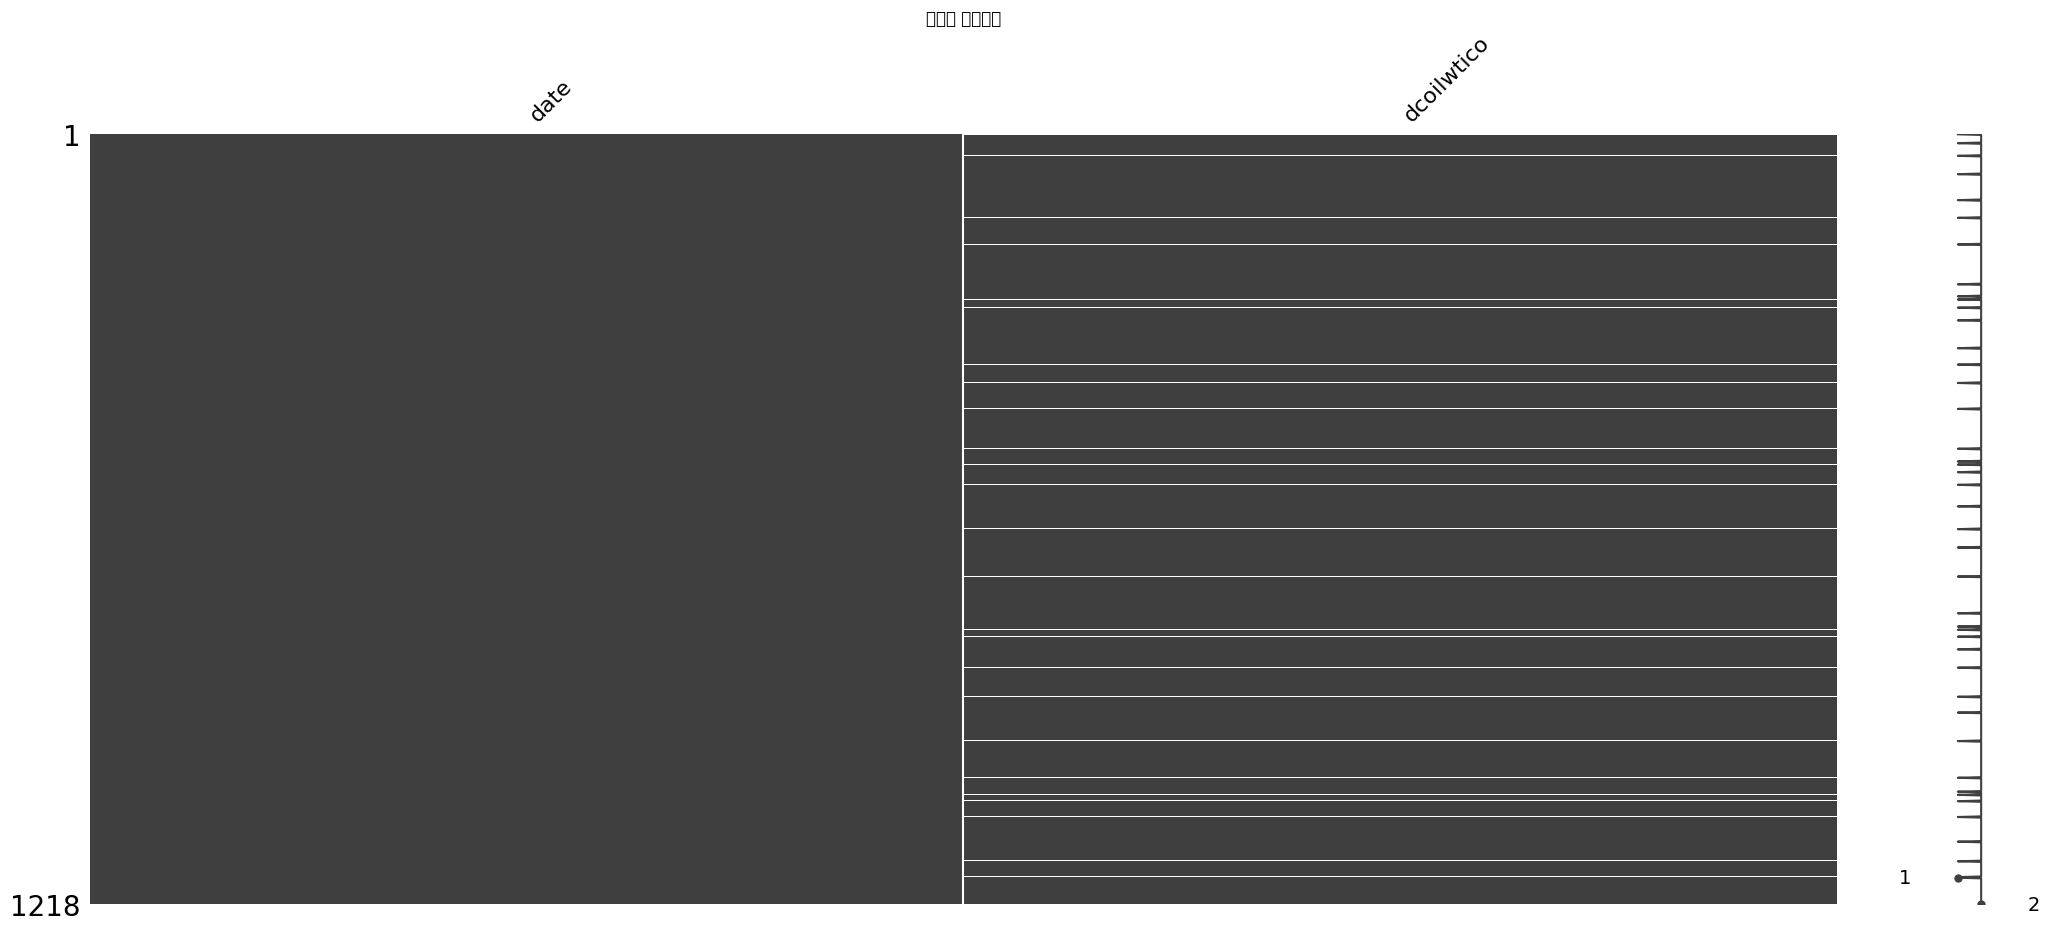

In [9]:

msno.matrix(oil)
plt.title("결측치 매트릭스")
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44201 (\N{HANGUL SYLLABLE GYEOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/u

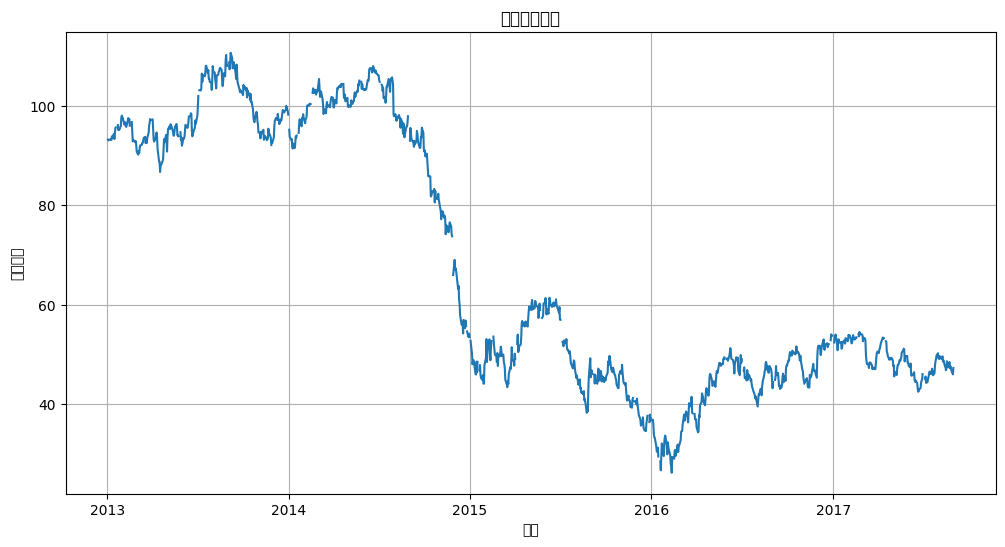

In [10]:
oil['date']=pd.to_datetime(oil['date'])
plt.figure(figsize=(12,6))
plt.plot(oil['date'],oil['dcoilwtico'])
plt.title("원유가격변화")
plt.xlabel("날짜")
plt.ylabel("원유가격")
plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48277 (\N{HANGUL SYLLABLE BEOB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54665 (\N{HANGUL SYLLABLE HAENG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

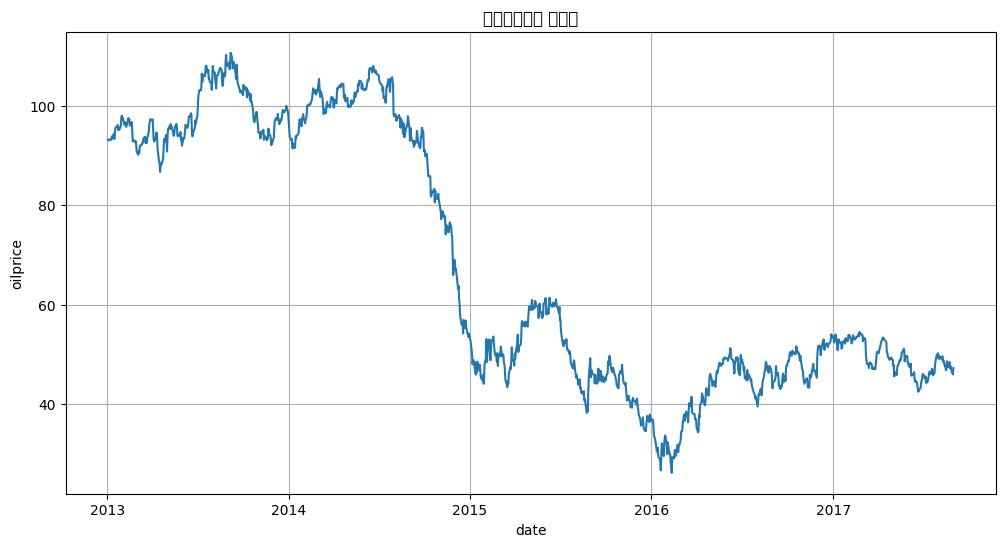

In [11]:
##보간법
oil_cleaned=oil.copy()

oil_cleaned['dcoilwtico']=oil_cleaned['dcoilwtico'].interpolate(method='linear')

plt.figure(figsize=(12,6))
plt.plot(oil_cleaned['date'],oil_cleaned['dcoilwtico'])
plt.title("보간법시행후 그래프")
plt.xlabel('date')
plt.ylabel('oilprice')
plt.grid(True)
plt.show()

In [12]:
family_bound=train.groupby('family')['sales'].apply(
    lambda x:x.quantile(0.75)+1.5*(x.quantile(0.75)-x.quantile(0.25
                                                               ))
)

train_enhanced=train.copy()
train_enhanced['upper_bound']=train_enhanced['family'].map(family_bound)
train_enhanced['is_outlier']=train_enhanced['sales']>train_enhanced['upper_bound']

total_outlier=train_enhanced['is_outlier'].sum()
total_ratio=train_enhanced['is_outlier'].mean()

In [13]:
print(total_outlier)
print(total_ratio)

200274
0.06673824547933811


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50676 (\N{HANGUL SYLLABLE YEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54032 (\N{HANGUL SYLLABLE PAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47588 (\N{HANGUL SYLLABLE MAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/u

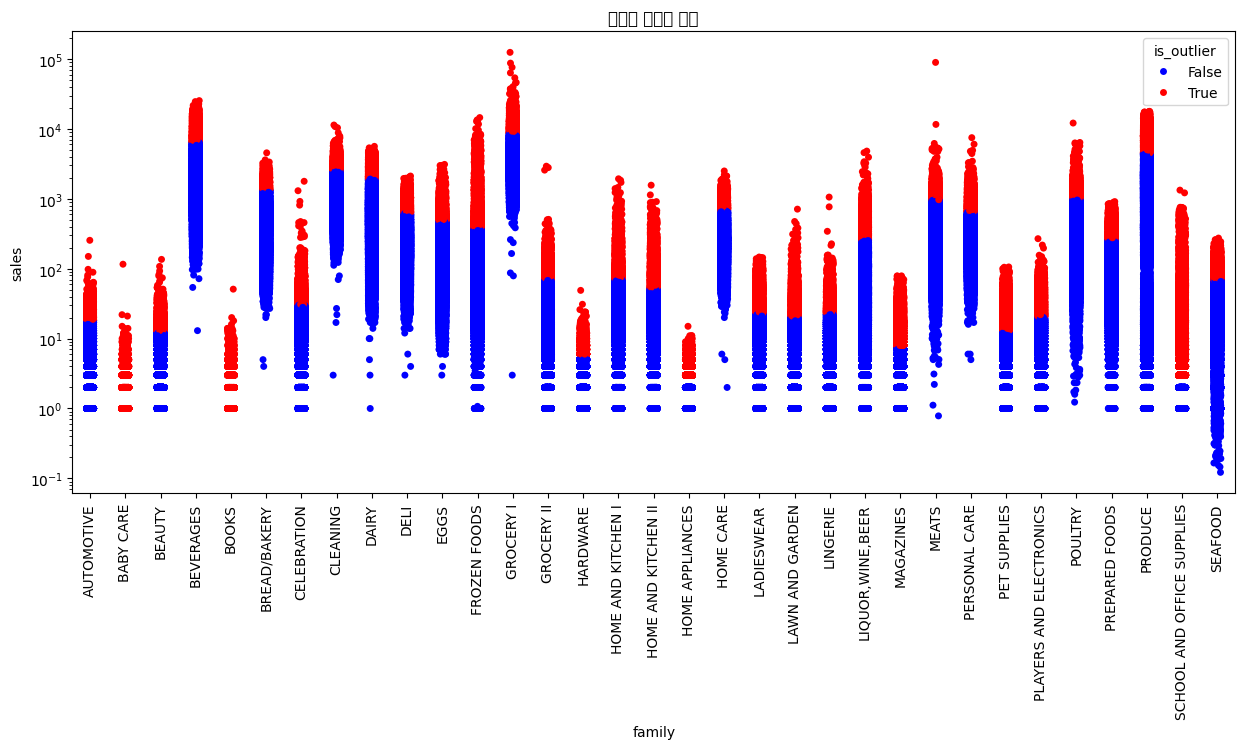

In [14]:
plt.figure(figsize=(15,6))
sns.stripplot(x='family',y='sales',hue=train_enhanced['is_outlier'],
              data=train_enhanced,palette={False:'blue',True:'red'})
plt.xticks(rotation=90)
plt.yscale('log')
plt.title('계열별 판매량 분포')
plt.show()

In [17]:
train_cleaned=train.copy()
train_cleaned.loc[train_enhanced['is_outlier'],'sales']= train_enhanced.loc[train_enhanced['is_outlier'],'upper_bound']
changed_count=(train['sales'] !=train_cleaned['sales']).sum()
print(changed_count)

200274


In [19]:
train_cleaned['date']=pd.to_datetime(train_cleaned['date'])
transactions['date']=pd.to_datetime(transactions['date'])
holidays_events['date']=pd.to_datetime(holidays_events['date'])
oil_cleaned['date']=pd.to_datetime(oil_cleaned['date'])

In [25]:
train_cleaned['year']=train_cleaned['date'].dt.year
train_cleaned['month']=train_cleaned['date'].dt.month
train_cleaned['day']=train_cleaned['date'].dt.day
train_cleaned['dayofweek']=train_cleaned['date'].dt.dayofweek
train_cleaned['weekend']=train_cleaned['dayofweek'].apply(lambda x: 1 if x>=5 else 0 )
train_cleaned['is_month_start']=train_cleaned['date'].dt.is_month_start
train_cleaned['is_month_end']=train_cleaned['date'].dt.is_month_end


In [29]:
day_sales=train_cleaned.groupby('dayofweek')['sales'].mean().reset_index()
day_sales['day_name']=day_sales['dayofweek'].map({
    0:'월요일',1:'화요일',2:'수요일',3:'목요일',4:'금요일',
    5:'토요일', 6:'일요일'
})

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50900 (\N{HANGUL SYLLABLE WEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

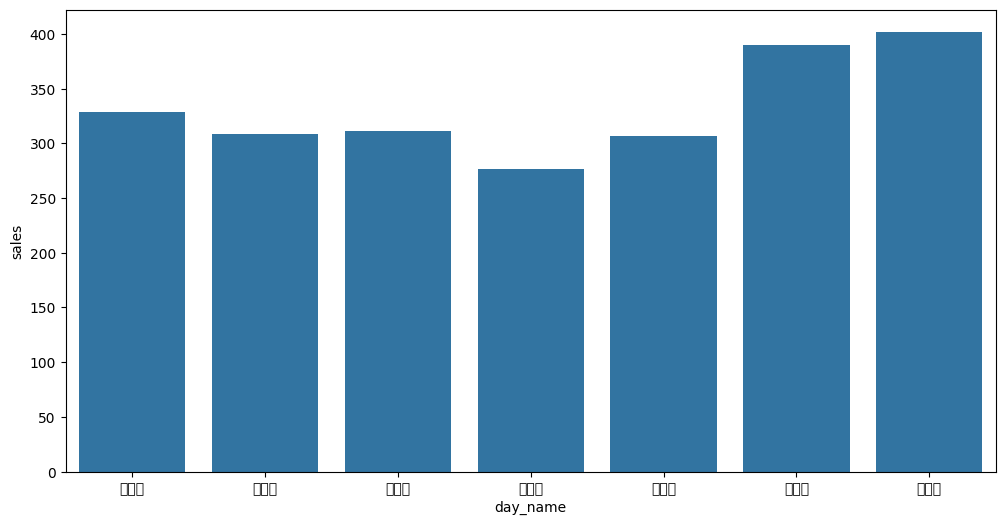

In [31]:
plt.figure(figsize=(12,6))
sns.barplot(x='day_name',y='sales',data=day_sales)
plt.title='sales by day'
plt.xlabel="day"
plt.ylabel='sales mean'
plt.show()

In [33]:
train_with_trans=pd.merge(
    train_cleaned,transactions,
    on=['date','store_nbr'],
    how='left'
)

train_with_store=pd.merge(
    train_with_trans,stores,
    on=['store_nbr'],
    how='left'
)

train_final=pd.merge(
    train_with_store,oil_cleaned,
    on=['date'],
    how='left'
)